In [1]:
import importlib
import subprocess
import sys
import types

def import_fix(package: str, pip_name: str = None) -> types.ModuleType:
    try:
        return importlib.import_module(package)
    except ModuleNotFoundError as e:
        if e.name != package.split(".")[0]:
            raise

        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            pip_name or package
        ])

        importlib.invalidate_caches()
        return importlib.import_module(package)

datasets = import_fix("datasets")
# pillow   = import_fix("pillow")
numpy    = import_fix("numpy")
plt      = import_fix("matplotlib")

try:
    import torch, torchvision
except Exception:
    # for cuda local, windows compatibile
    %pip install torch==2.11.0 torchvision==0.26.0 --index-url https://download.pytorch.org/whl/cu128

from typing import List, Tuple, Dict

c:\Users\jan\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# -L for shorter output
!nvidia-smi -L

GPU 0: NVIDIA GeForce RTX 2060 (UUID: GPU-ba23c874-bcac-9e5c-3f94-8f3e9fcaf22b)


In [3]:
from datasets import load_dataset
from functools import cache

@cache
def get_dataset():
    return load_dataset("uoft-cs/cifar10")

dataset = get_dataset()

train = dataset["train"]
test = dataset["test"]

image = train[0]["img"]
label = train[0]["label"]


In [4]:
label_names: List[str] = train.features["label"].names

print(image.size) # no error, good
print(f"Labels: {[ l for l in label_names ]}")

(32, 32)
Labels: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


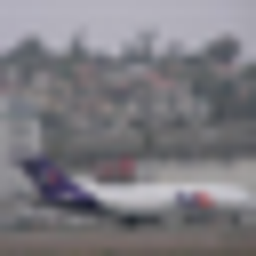

Image class: airplane


In [5]:
from IPython.display import display # for linters and global compability

display(image.resize((256, 256)))
print(f"Image class: {label_names[label]}")

In [6]:
from torch import nn
device = str(torch.accelerator.current_accelerator().type) if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [7]:
INPUT_LAYER_SIZE: int  = image.size[0] * image.size[1] * 3 # 32 * 32 * 3
OUTPUT_LAYER_SIZE: int = 10 # there are 10 classes of images

SEED: int = 7312
torch.manual_seed(SEED)

print(f"{INPUT_LAYER_SIZE = }, {OUTPUT_LAYER_SIZE = }")

INPUT_LAYER_SIZE = 3072, OUTPUT_LAYER_SIZE = 10


In [8]:
def tensorise_image(image) -> torch.Tensor:
    tensorised_image = torch.from_numpy(numpy.array(image))
    # this is - image is [32, 32, 3] -> [3, 32, 32]
    return (tensorised_image.permute(2, 0, 1).float() / 255.0).unsqueeze(0)

# torch.tensor and torch.Tensor don't work the same
# train_set_images: torch.Tensor = torch.cat(
#     [ tensorise_image(img["img"]) for img in train ]
# )

# train_set_labels: torch.Tensor = torch.tensor(
#     list(train["label"])
# )

# test_set_images: torch.Tensor = torch.cat(
#     [ tensorise_image(img["img"]) for img in test ]
# )

# test_set_labels: torch.Tensor = torch.tensor(
#     list(test["label"])
# )

# this produces list of maps -> [ ... {img: 3x32x32, label: [0-9]} ... ]
train_set: torch.Tensor = train.with_format("torch")[:] # [:] <- this makes a single tensor instead of array of smaller ones
test_set: torch.Tensor  = test.with_format("torch")[:]  # thus a dict of "img": all images (big tensor), "labels"

print(type(train_set), train_set.keys())
print(type(train_set["img"]), train_set["img"][:1].shape, train_set["img"].dtype)

train_set_images: torch.Tensor = train_set["img"].float() / 255.0
test_set_images: torch.Tensor  = test_set["img"].float() / 255.0

train_set_labels: torch.Tensor = train_set["label"]
test_set_labels: torch.Tensor  = test_set["label"]

print(train_set_images.dtype)


<class 'dict'> dict_keys(['img', 'label'])
<class 'torch.Tensor'> torch.Size([1, 3, 32, 32]) torch.uint8
torch.float32


In [9]:
class DeepCifar10(nn.Module):
    def __init__(self, hidden_layers_number: int = 10, layers_width: int = 256):
        super().__init__()

        self.flatten = nn.Flatten()

        self.hidden_layers_number: int = hidden_layers_number
        self.hidden_layers_width: int  = layers_width
        layers: List[nn.Module] = []

        # input
        layers += [
            nn.Linear(INPUT_LAYER_SIZE, self.hidden_layers_width),
            nn.ReLU()
        ]

        # hidden
        for _ in range(self.hidden_layers_number):
            layers += [
                nn.Linear(self.hidden_layers_width, self.hidden_layers_width),
                nn.ReLU()
            ]

        # output
        layers += [
            nn.Linear(self.hidden_layers_width, OUTPUT_LAYER_SIZE),
        ]

        self.layers: nn.Sequential = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(self.flatten(x))

class ConvCifar10(nn.Module):
    def __init__(
        self,
        stages_channels: List[List[int]] = [[20, 20, 20], [40, 40, 40], [60, 60, 80]]
    ):
        super().__init__()

        self.stages_channels: List[List[int]] = stages_channels
        self.channels: int                    = 3 # RGB
        layers: List[nn.Module]               = []

        in_channels: int = self.channels

        # hidden: every conv is plain; maxpool halves the size between stages
        for stage_index, stage_channels in enumerate(self.stages_channels):
            if stage_index > 0:
                layers += [ nn.MaxPool2d(2) ]
            for out_channels in stage_channels:
                layers += [
                    nn.Conv2d(in_channels, out_channels, 3, padding=1),
                    nn.ReLU()
                ]
                in_channels = out_channels

        layers += [
            nn.Conv2d(in_channels, OUTPUT_LAYER_SIZE, 1),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        ]

        self.layers: nn.Sequential = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


In [10]:
class HighwayLayer(nn.Module):
    def __init__(self, input_size: int, output_size: int, initial_bias: int = -1.0):
        super().__init__()

        self.input_size: int  = input_size
        self.output_size: int = output_size

        # H : affine transformation
        self.H: nn.Module    = nn.Linear(input_size, output_size)
        self.relu: nn.Module = nn.ReLU()

        # T : Transform gate
        self.T: nn.Module       = nn.Linear(input_size, output_size)
        self.sigmoid: nn.Module = nn.Sigmoid()
        nn.init.constant_(self.T.bias, initial_bias) # paper uses negative values

        # C : not using Carry gate; C = (1 - T)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h: torch.Tensor = self.relu(self.H(x))
        t: torch.Tensor = self.sigmoid(self.T(x))
        c: torch.Tensor = (1.0 - t)

        return h * t + x * c

class HighwayCifar10(nn.Module):
    def __init__(self, hidden_layers_number: int = 10, layers_width: int = 256):
        super().__init__()

        self.flatten = nn.Flatten()

        self.hidden_layers_number: int = hidden_layers_number
        self.hidden_layers_width: int  = layers_width
        layers: List[nn.Module] = []

        # input
        layers += [
            nn.Linear(INPUT_LAYER_SIZE, self.hidden_layers_width),
            nn.ReLU()
        ]

        # hidden
        for _ in range(self.hidden_layers_number):
            layers += [
                HighwayLayer(self.hidden_layers_width, self.hidden_layers_width)
            ]

        # output
        layers += [
            nn.Linear(self.hidden_layers_width, OUTPUT_LAYER_SIZE),
        ]

        self.layers: nn.Sequential = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(self.flatten(x))


In [11]:
class HighwayConvLayer(nn.Module):
    def __init__(
        self, channels: int,
        kernel_size: int = 2,
        initial_bias: float = -2.5
    ):
        super().__init__()

        self.channels: int    = channels
        self.kernel_size: int = kernel_size

        # H : affine transformation
        self.H: nn.Module    = nn.Conv2d(channels, channels, kernel_size, padding=kernel_size // 2)
        self.relu: nn.Module = nn.ReLU()

        # T : Transform gate
        self.T: nn.Module    = nn.Conv2d(channels, channels, kernel_size, padding=kernel_size // 2)
        self.sigmoid: nn.Module = nn.Sigmoid()
        nn.init.constant_(self.T.bias, initial_bias) # paper uses negative values

        # C : not using Carry gate; C = (1 - T)

        # padding is important for convolutions as
        # dimensionality of x, y, H, T must be the same

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h: torch.Tensor = self.relu(self.H(x))
        t: torch.Tensor = self.sigmoid(self.T(x))
        c: torch.Tensor = (1.0 - t)

        return h * t + x * c

class HighwayConvCifar10(nn.Module):
    def __init__(
        self,
        channels_per_stage: List[List[int]] = [[16, 16, 16], [32, 32, 32], [48, 48, 64]],
        initial_bias: float = -2.5
    ):
        super().__init__()

        self.channels_per_stage: List[List[int]] = channels_per_stage
        self.channels: int                       = 3 # RGB
        self.kernel_size: int                    = 3
        layers: List[nn.Module]                  = []

        in_channels: int = self.channels


        # hidden: same channels in and out -> highway, channels change -> plain with padding
        for stage_index, stage_channels in enumerate(self.channels_per_stage):
            if stage_index > 0:
                layers += [ nn.MaxPool2d(2) ]

            for out_channels in stage_channels:
                if out_channels == in_channels:
                    layers += [ HighwayConvLayer(out_channels, self.kernel_size, initial_bias) ]
                else:
                    layers += [
                        nn.Conv2d(in_channels, out_channels, self.kernel_size, padding=1),
                        nn.ReLU()
                    ]
                in_channels = out_channels

        # output
        layers += [
            nn.Conv2d(in_channels, OUTPUT_LAYER_SIZE, 1),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        ]

        self.layers: nn.Sequential = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)

In [12]:
my_nn: DeepCifar10                  = DeepCifar10(10, 128).to(device)
my_highway_nn: HighwayCifar10       = HighwayCifar10(10, 128).to(device)
my_conv_nn: ConvCifar10             = ConvCifar10([[20, 20, 20], [40, 40, 40], [60, 60, 80]]).to(device)
my_conv_highway: HighwayConvCifar10 = HighwayConvCifar10([[16, 16, 16], [32, 32, 32], [48, 48, 64]], -2.5).to(device)

In [13]:
print(train_set_images.shape, train_set_images[0].shape)

torch.Size([50000, 3, 32, 32]) torch.Size([3, 32, 32])


In [14]:
from torch.utils.data import DataLoader, Dataset, TensorDataset

# returns loss and correct hits totals
def training_loop(
    dnn: nn.Module,
    dataset: Dataset,
    loss_function: nn.Module,
    optimizer: torch.optim.Optimizer
) -> Tuple[float, int]:
    dnn.train()
    data_loader: DataLoader = DataLoader(dataset, 128, shuffle = True)
    # optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

    total_loss: torch.Tensor   = torch.zeros((), device=device)
    correct_hits: torch.Tensor = torch.zeros((), dtype=torch.long, device=device)

    for x, y in data_loader:
        x_dev, y_dev = x, y
        # x_dev, y_dev = x.to(device), y.to(device)

        almost_prediction: torch.Tensor = dnn(x_dev)
        loss: torch.Tensor              = loss_function(almost_prediction, y_dev)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # loss is average loss over all outputs so, sum(y_err) / size(y_err) * size(y_err) = sum(y_Err)
        total_loss   += loss.detach() * y_dev.numel()
        correct_hits += (almost_prediction.argmax(1) == y_dev).sum()

    return (total_loss.item(), correct_hits.item())


In [15]:

@torch.no_grad()
def evaluate(dnn: nn.Module, validation_dataset: Dataset, loss_function: nn.Module) -> Tuple[float, int]:
    dnn.eval()
    total_loss: float = 0.0
    correct_hits: int = 0

    for x, y in DataLoader(validation_dataset, 512):
        x_dev, y_dev = x.to(device), y.to(device)
        prediction: torch.Tensor = dnn(x_dev)
        total_loss   += loss_function(prediction, y_dev).item() * len(y_dev)
        correct_hits += (prediction.argmax(1) == y_dev).sum().item()

    return (total_loss, correct_hits)



In [16]:
def augment_dataset(dataset: TensorDataset, max_shift: int = 4) -> TensorDataset:
    images, labels = dataset.tensors
    images_number, _, height, width = images.shape
    device = images.device

    # translation: pad with zeros, then cut a 32x32 window at a random offset (0..8, 4 = no shift)
    padded: torch.Tensor  = nn.functional.pad(images, (max_shift, max_shift, max_shift, max_shift))
    shift_y: torch.Tensor = torch.randint(0, 2 * max_shift + 1, (images_number,), device=device)
    shift_x: torch.Tensor = torch.randint(0, 2 * max_shift + 1, (images_number,), device=device)

    shifted: torch.Tensor = torch.empty_like(images)
    # one pass per possible offset (9 x 9 = 81), each takes all images that drew it
    for dy in range(2 * max_shift + 1):
        for dx in range(2 * max_shift + 1):
            chosen: torch.Tensor = (shift_y == dy) & (shift_x == dx)
            shifted[chosen] = padded[chosen, :, dy : dy + height, dx : dx + width]
    del padded

    # mirroring: flip half of the images left-right
    flipped: torch.Tensor = torch.rand(images_number, device=device) < 0.5
    shifted[flipped] = shifted[flipped].flip(3)

    return TensorDataset(shifted, labels)

In [17]:
train_tensor_dataset: Dataset = TensorDataset(
    train_set_images[ : int(len(train_set_images) * 0.9)],
    train_set_labels[: int(len(train_set_labels) * 0.9)]
)

validation_tensor_dataset: Dataset = TensorDataset(
    train_set_images[int(len(train_set_images) * 0.9) : ],
    train_set_labels[int(len(train_set_labels) * 0.9) : ]
)

train_tensor_dataset = TensorDataset(
    *(t.to(device) for t in train_tensor_dataset.tensors)
)

validation_tensor_dataset = TensorDataset(
    *(t.to(device) for t in validation_tensor_dataset.tensors)
)


training_data_base: List[Tuple[float, int]]   = []
validation_data_base: List[Tuple[float, int]] = []

training_data_highway: List[Tuple[float, int]]   = []
validation_data_highway: List[Tuple[float, int]] = []

torch.manual_seed(SEED)
optimizer = torch.optim.SGD(my_nn.parameters(), lr=0.01, momentum=0.9)
for it in range(100):
    training_data_base.append(training_loop(my_nn, augment_dataset(train_tensor_dataset), nn.CrossEntropyLoss(), optimizer))
    validation_data_base.append(evaluate(my_nn, validation_tensor_dataset, nn.CrossEntropyLoss()))
    if (it + 1) % 10 == 0:
        print(f"Progress PLAIN ... {it + 1} / {100}")

torch.manual_seed(SEED)
optimizer = torch.optim.SGD(my_highway_nn.parameters(), lr=0.01, momentum=0.9)
for it in range(100):
    training_data_highway.append(training_loop(my_highway_nn, augment_dataset(train_tensor_dataset), nn.CrossEntropyLoss(), optimizer))
    validation_data_highway.append(evaluate(my_highway_nn, validation_tensor_dataset, nn.CrossEntropyLoss()))
    if (it + 1) % 10 == 0:
        print(f"Progress HIGHWAY ... {it + 1} / {100}")


Progress PLAIN ... 10 / 100%
Progress PLAIN ... 20 / 100%
Progress PLAIN ... 30 / 100%
Progress PLAIN ... 40 / 100%
Progress PLAIN ... 50 / 100%
Progress PLAIN ... 60 / 100%
Progress PLAIN ... 70 / 100%
Progress PLAIN ... 80 / 100%
Progress PLAIN ... 90 / 100%
Progress PLAIN ... 100 / 100%
Progress HIGHWAY ... 10 / 100
Progress HIGHWAY ... 20 / 100
Progress HIGHWAY ... 30 / 100
Progress HIGHWAY ... 40 / 100
Progress HIGHWAY ... 50 / 100
Progress HIGHWAY ... 60 / 100
Progress HIGHWAY ... 70 / 100
Progress HIGHWAY ... 80 / 100
Progress HIGHWAY ... 90 / 100
Progress HIGHWAY ... 100 / 100


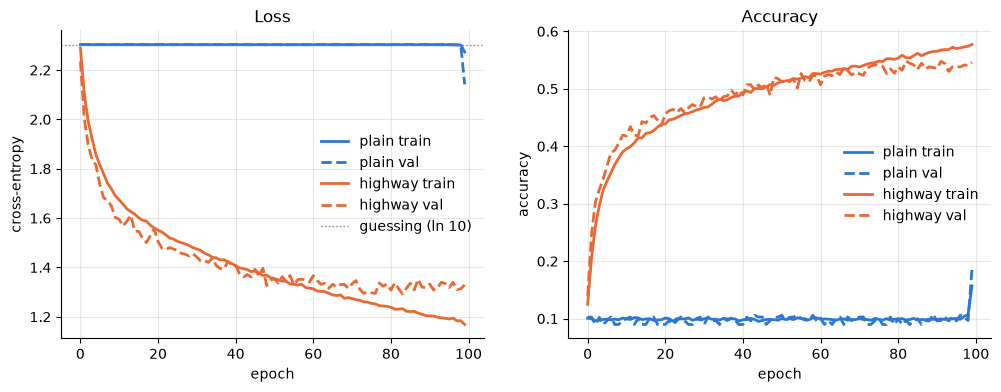

In [18]:
import matplotlib.pyplot as plt

def per_sample(history: List[Tuple[float, int]], dataset: Dataset) -> Tuple[List[float], List[float]]:
    n: int = len(dataset)
    return [loss / n for loss, _ in history], [hits / n for _, hits in history]

runs = [
    ("plain",   "#2a78d6", training_data_base,    validation_data_base),
    ("highway", "#eb6834", training_data_highway, validation_data_highway),
]

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

for name, color, train_history, val_history in runs:
    train_loss, train_acc = per_sample(train_history, train_tensor_dataset)
    val_loss, val_acc     = per_sample(val_history, validation_tensor_dataset)

    ax_loss.plot(train_loss, color=color, lw=2, label=f"{name} train")
    ax_loss.plot(val_loss,   color=color, lw=2, ls="--", label=f"{name} val")
    ax_acc.plot(train_acc,   color=color, lw=2, label=f"{name} train")
    ax_acc.plot(val_acc,     color=color, lw=2, ls="--", label=f"{name} val")

ax_loss.axhline(numpy.log(10), color="gray", lw=1, ls=":", label="guessing (ln 10)")

ax_loss.set(title="Loss", xlabel="epoch", ylabel="cross-entropy")
ax_acc.set(title="Accuracy", xlabel="epoch", ylabel="accuracy")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)

plt.show()

In [19]:
def run_training(dnn: nn.Module, name: str, epochs: int = 100) -> Tuple[List[Tuple[float, int]], List[Tuple[float, int]]]:
    torch.manual_seed(SEED)
    optimizer = torch.optim.SGD(dnn.parameters(), lr=0.01, momentum=0.9)
    training_data: List[Tuple[float, int]]   = []
    validation_data: List[Tuple[float, int]] = []

    for it in range(epochs):
        training_data.append(training_loop(dnn, augment_dataset(train_tensor_dataset), nn.CrossEntropyLoss(), optimizer))
        validation_data.append(evaluate(dnn, validation_tensor_dataset, nn.CrossEntropyLoss()))
        if (it + 1) % 10 == 0:
            print(f"{name}: epoch {it + 1}/{epochs}")

    return training_data, validation_data

torch.manual_seed(SEED)
my_nn: DeepCifar10                     = DeepCifar10(9, 71).to(device)
my_highway_nn: HighwayCifar10          = HighwayCifar10(9, 50).to(device)
my_conv_nn: ConvCifar10                = ConvCifar10().to(device)
my_highway_conv_nn: HighwayConvCifar10 = HighwayConvCifar10().to(device)

for dnn in [my_nn, my_highway_nn, my_conv_nn, my_highway_conv_nn]:
    print(f"{type(dnn).__name__}: {sum(p.numel() for p in dnn.parameters()):,} params")

training_data_base, validation_data_base                 = run_training(my_nn, "PLAIN")
training_data_highway, validation_data_highway           = run_training(my_highway_nn, "HIGHWAY")
training_data_conv, validation_data_conv                 = run_training(my_conv_nn, "CONV")
training_data_highway_conv, validation_data_highway_conv = run_training(my_highway_conv_nn, "HIGHWAY CONV")

DeepCifar10: 264,911 params
HighwayCifar10: 200,060 params
ConvCifar10: 142,130 params
HighwayConvCifar10: 135,162 params
PLAIN: epoch 10/100
PLAIN: epoch 20/100
PLAIN: epoch 30/100
PLAIN: epoch 40/100
PLAIN: epoch 50/100
PLAIN: epoch 60/100
PLAIN: epoch 70/100
PLAIN: epoch 80/100
PLAIN: epoch 90/100
PLAIN: epoch 100/100
HIGHWAY: epoch 10/100
HIGHWAY: epoch 20/100
HIGHWAY: epoch 30/100
HIGHWAY: epoch 40/100
HIGHWAY: epoch 50/100
HIGHWAY: epoch 60/100
HIGHWAY: epoch 70/100
HIGHWAY: epoch 80/100
HIGHWAY: epoch 90/100
HIGHWAY: epoch 100/100
CONV: epoch 10/100
CONV: epoch 20/100
CONV: epoch 30/100
CONV: epoch 40/100
CONV: epoch 50/100
CONV: epoch 60/100
CONV: epoch 70/100
CONV: epoch 80/100
CONV: epoch 90/100
CONV: epoch 100/100
HIGHWAY CONV: epoch 10/100
HIGHWAY CONV: epoch 20/100
HIGHWAY CONV: epoch 30/100
HIGHWAY CONV: epoch 40/100
HIGHWAY CONV: epoch 50/100
HIGHWAY CONV: epoch 60/100
HIGHWAY CONV: epoch 70/100
HIGHWAY CONV: epoch 80/100
HIGHWAY CONV: epoch 90/100
HIGHWAY CONV: epoch 10

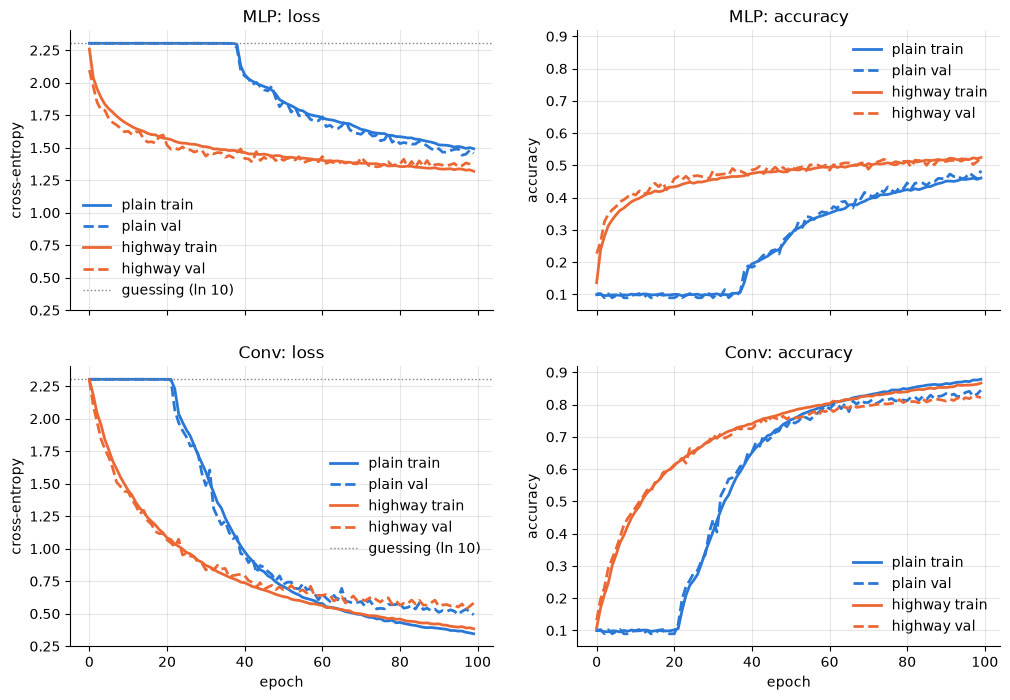

In [20]:
families = [
    ("MLP",  [("plain",   "#2a78d6", training_data_base,         validation_data_base),
              ("highway", "#eb6834", training_data_highway,      validation_data_highway)]),
    ("Conv", [("plain",   "#2a78d6", training_data_conv,         validation_data_conv),
              ("highway", "#eb6834", training_data_highway_conv, validation_data_highway_conv)]),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey="col")

for (family, runs), (ax_loss, ax_acc) in zip(families, axes):
    for name, color, train_history, val_history in runs:
        train_loss, train_acc = per_sample(train_history, train_tensor_dataset)
        val_loss, val_acc     = per_sample(val_history, validation_tensor_dataset)

        ax_loss.plot(train_loss, color=color, lw=2, label=f"{name} train")
        ax_loss.plot(val_loss,   color=color, lw=2, ls="--", label=f"{name} val")
        ax_acc.plot(train_acc,   color=color, lw=2, label=f"{name} train")
        ax_acc.plot(val_acc,     color=color, lw=2, ls="--", label=f"{name} val")

    ax_loss.axhline(numpy.log(10), color="gray", lw=1, ls=":", label="guessing (ln 10)")
    ax_loss.set(title=f"{family}: loss", ylabel="cross-entropy")
    ax_acc.set(title=f"{family}: accuracy", ylabel="accuracy")

for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
for ax in axes[1]:
    ax.set_xlabel("epoch")

plt.show()


In [21]:
torch.manual_seed(SEED)

nn_10: DeepCifar10  = DeepCifar10(9, 71).to(device)
nn_20: DeepCifar10  = DeepCifar10(19, 71).to(device)
nn_50: DeepCifar10  = DeepCifar10(49, 71).to(device)
nn_100: DeepCifar10 = DeepCifar10(99, 71).to(device)

nn_highway_10: HighwayCifar10  = HighwayCifar10(9, 50).to(device)
nn_highway_20: HighwayCifar10  = HighwayCifar10(19, 50).to(device)
nn_highway_50: HighwayCifar10  = HighwayCifar10(49, 50).to(device)
nn_highway_100: HighwayCifar10 = HighwayCifar10(99, 50).to(device)

networks: List[nn.Module] = [nn_10, nn_20, nn_50, nn_100, nn_highway_10, nn_highway_20, nn_highway_50, nn_highway_100]

for dnn in networks:
    print(f"{type(dnn).__name__}: {sum(p.numel() for p in dnn.parameters()):,} params")

outputs = [
    (*run_training(dnn, dnn._get_name()), str(type(dnn).__name__))
       for dnn in networks
]


DeepCifar10: 264,911 params
DeepCifar10: 316,031 params
DeepCifar10: 469,391 params
DeepCifar10: 724,991 params
HighwayCifar10: 200,060 params
HighwayCifar10: 251,060 params
HighwayCifar10: 404,060 params
HighwayCifar10: 659,060 params
DeepCifar10: epoch 10/100
DeepCifar10: epoch 20/100
DeepCifar10: epoch 30/100
DeepCifar10: epoch 40/100
DeepCifar10: epoch 50/100
DeepCifar10: epoch 60/100
DeepCifar10: epoch 70/100
DeepCifar10: epoch 80/100
DeepCifar10: epoch 90/100
DeepCifar10: epoch 100/100
DeepCifar10: epoch 10/100
DeepCifar10: epoch 20/100
DeepCifar10: epoch 30/100
DeepCifar10: epoch 40/100
DeepCifar10: epoch 50/100
DeepCifar10: epoch 60/100
DeepCifar10: epoch 70/100
DeepCifar10: epoch 80/100
DeepCifar10: epoch 90/100
DeepCifar10: epoch 100/100
DeepCifar10: epoch 10/100
DeepCifar10: epoch 20/100
DeepCifar10: epoch 30/100
DeepCifar10: epoch 40/100
DeepCifar10: epoch 50/100
DeepCifar10: epoch 60/100
DeepCifar10: epoch 70/100
DeepCifar10: epoch 80/100
DeepCifar10: epoch 90/100
DeepCifa

In [22]:
import json

DEPTHS: List[int]      = [10, 20, 50, 100]
COLORS: Dict[str, str] = {"plain": "#2a78d6", "highway": "#eb6834"}

# outputs only has the class name, so take kind and depth from the network itself
sweep: Dict[Tuple[str, int], Tuple[List[Tuple[float, int]], List[Tuple[float, int]]]] = {}
for dnn, (train_history, val_history, _) in zip(networks, outputs):
    kind: str  = "highway" if isinstance(dnn, HighwayCifar10) else "plain"
    depth: int = dnn.hidden_layers_number + 1
    sweep[(kind, depth)] = (train_history, val_history)

with open("depth_sweep_aug.json", "w") as f:
    json.dump({f"{kind}_{depth}": histories for (kind, depth), histories in sweep.items()}, f)

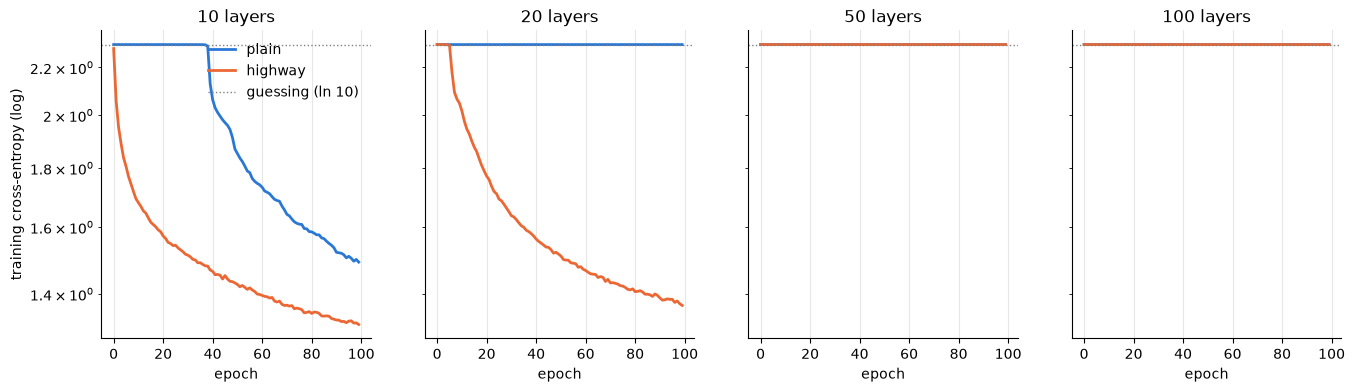

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

for ax, depth in zip(axes, DEPTHS):
    for kind in ["plain", "highway"]:
        train_history, _ = sweep[(kind, depth)]
        train_loss, _    = per_sample(train_history, train_tensor_dataset)
        ax.plot(train_loss, color=COLORS[kind], lw=2, label=kind)

    ax.axhline(numpy.log(10), color="gray", lw=1, ls=":", label="guessing (ln 10)")
    ax.set(title=f"{depth} layers", xlabel="epoch", yscale="log")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("training cross-entropy (log)")
axes[0].legend(frameon=False)
plt.show()

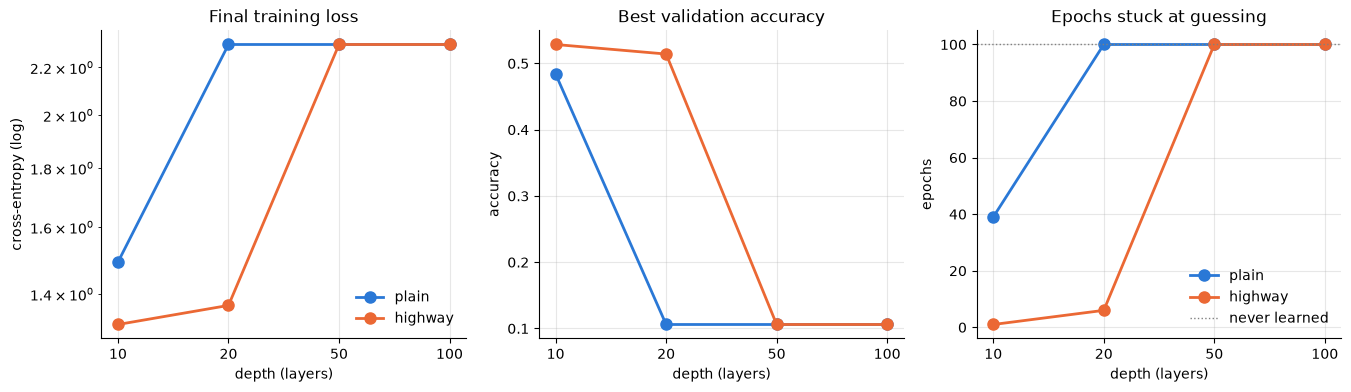

In [24]:
def epochs_at_guessing(train_loss: List[float]) -> int:
    for epoch, loss in enumerate(train_loss):
        if loss < numpy.log(10) - 0.1:
            return epoch
    return len(train_loss)

fig, (ax_loss, ax_acc, ax_stuck) = plt.subplots(1, 3, figsize=(16, 4))
x = list(range(len(DEPTHS)))

for kind in ["plain", "highway"]:
    final_loss: List[float] = []
    best_acc: List[float]   = []
    stuck: List[int]        = []

    for depth in DEPTHS:
        train_history, val_history = sweep[(kind, depth)]
        train_loss, _ = per_sample(train_history, train_tensor_dataset)
        _, val_acc    = per_sample(val_history, validation_tensor_dataset)

        final_loss.append(train_loss[-1])
        best_acc.append(max(val_acc))
        stuck.append(epochs_at_guessing(train_loss))

    style = dict(color=COLORS[kind], lw=2, marker="o", ms=8, label=kind)
    ax_loss.plot(x, final_loss, **style)
    ax_acc.plot(x, best_acc, **style)
    ax_stuck.plot(x, stuck, **style)

ax_stuck.axhline(len(train_loss), color="gray", lw=1, ls=":", label="never learned")

ax_loss.set(title="Final training loss", ylabel="cross-entropy (log)", yscale="log")
ax_acc.set(title="Best validation accuracy", ylabel="accuracy")
ax_stuck.set(title="Epochs stuck at guessing", ylabel="epochs")
for ax in (ax_loss, ax_acc, ax_stuck):
    ax.set(xticks=x, xticklabels=[str(d) for d in DEPTHS], xlabel="depth (layers)")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
ax_loss.legend(frameon=False)
ax_stuck.legend(frameon=False)
plt.show()

In [30]:
early_stop_highway_conv_nn: HighwayConvCifar10 = HighwayConvCifar10().to(device)
train_out_early, validation_out_early = run_training(early_stop_highway_conv_nn, "earlystop", 40)


earlystop: epoch 10/40
earlystop: epoch 20/40
earlystop: epoch 30/40
earlystop: epoch 40/40


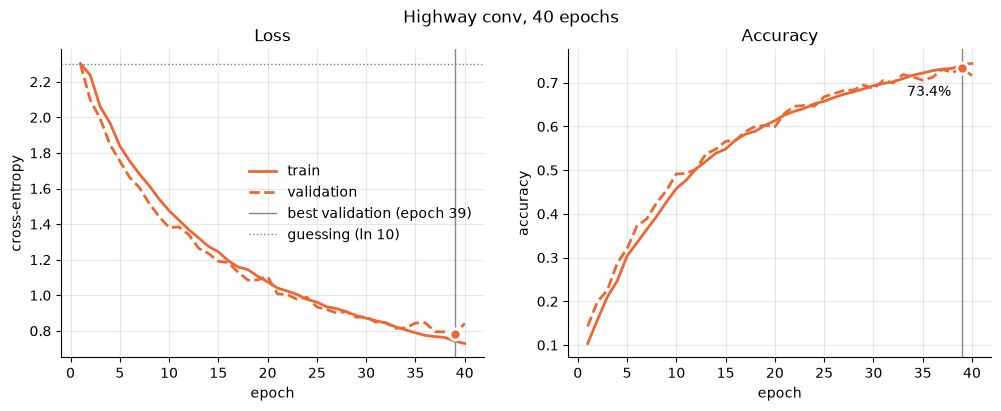

In [33]:
train_loss, train_acc           = per_sample(train_out_early, train_tensor_dataset)
validation_loss, validation_acc = per_sample(validation_out_early, validation_tensor_dataset)
epochs: List[int] = list(range(1, len(train_loss) + 1))

# best validation epoch: where early stopping would stop
best_index: int = int(numpy.argmax(validation_acc))
best_epoch: int = epochs[best_index]

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for ax, train_values, validation_values in [
    (ax_loss, train_loss, validation_loss),
    (ax_acc,  train_acc,  validation_acc),
]:
    ax.plot(epochs, train_values,      color="#eb6834", lw=2,          label="train")
    ax.plot(epochs, validation_values, color="#eb6834", lw=2, ls="--", label="validation")
    ax.axvline(best_epoch, color="#898781", lw=1, label=f"best validation (epoch {best_epoch})")
    ax.plot(best_epoch, validation_values[best_index], "o", ms=8, color="#eb6834", mec="white", mew=2, zorder=3)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

ax_loss.axhline(numpy.log(10), color="gray", lw=1, ls=":", label="guessing (ln 10)")

# label only the best point, on the side with more room
on_right: bool = best_index < len(epochs) / 2
ax_acc.annotate(
    f"{validation_acc[best_index]:.1%}",
    (best_epoch, validation_acc[best_index]),
    xytext=(8 if on_right else -8, -20), textcoords="offset points",
    ha="left" if on_right else "right",
)

ax_loss.set(title="Loss", ylabel="cross-entropy")
ax_acc.set(title="Accuracy", ylabel="accuracy")
ax_loss.legend(frameon=False)
fig.suptitle(f"Highway conv, {len(epochs)} epochs")
plt.show()

In [27]:
test_tensor_dataset: Dataset = TensorDataset(test_set_images, test_set_labels)

for name, dnn in [("plain", my_nn), ("highway", my_highway_nn), ("conv", my_conv_nn), ("highway conv", my_highway_conv_nn)]:
    _, hits = evaluate(dnn, test_tensor_dataset, nn.CrossEntropyLoss())
    print(f"{name}: test accuracy {hits / len(test_tensor_dataset):.2%}")

plain: test accuracy 47.75%
highway: test accuracy 52.51%
conv: test accuracy 84.45%
highway conv: test accuracy 82.36%


In [28]:
_, hits = evaluate(nn_10, test_tensor_dataset, nn.CrossEntropyLoss())
print(f"nn_10 test accuracy {hits / len(test_tensor_dataset):.2%}")
_, hits = evaluate(nn_20, test_tensor_dataset, nn.CrossEntropyLoss())
print(f"nn_20 test accuracy {hits / len(test_tensor_dataset):.2%}")
_, hits = evaluate(nn_50, test_tensor_dataset, nn.CrossEntropyLoss())
print(f"nn_50 test accuracy {hits / len(test_tensor_dataset):.2%}")
_, hits = evaluate(nn_100, test_tensor_dataset, nn.CrossEntropyLoss())
print(f"nn_100 test accuracy {hits / len(test_tensor_dataset):.2%}")

_, hits = evaluate(nn_highway_10, test_tensor_dataset, nn.CrossEntropyLoss())
print(f"nn_highway_10 test accuracy {hits / len(test_tensor_dataset):.2%}")
_, hits = evaluate(nn_highway_20, test_tensor_dataset, nn.CrossEntropyLoss())
print(f"nn_highway_20 test accuracy {hits / len(test_tensor_dataset):.2%}")
_, hits = evaluate(nn_highway_50, test_tensor_dataset, nn.CrossEntropyLoss())
print(f"nn_highway_50 test accuracy {hits / len(test_tensor_dataset):.2%}")
_, hits = evaluate(nn_highway_100, test_tensor_dataset, nn.CrossEntropyLoss())
print(f"nn_highway_100 test accuracy {hits / len(test_tensor_dataset):.2%}")

nn_10 test accuracy 47.75%
nn_20 test accuracy 10.00%
nn_50 test accuracy 10.00%
nn_100 test accuracy 10.00%
nn_highway_10 test accuracy 52.23%
nn_highway_20 test accuracy 50.50%
nn_highway_50 test accuracy 10.00%
nn_highway_100 test accuracy 10.00%


In [32]:
_, hits = evaluate(early_stop_highway_conv_nn, test_tensor_dataset, nn.CrossEntropyLoss())
print(f"early_stop_highway_conv_nn test accuracy {hits / len(test_tensor_dataset):.2%}")

early_stop_highway_conv_nn test accuracy 71.96%
